In [1]:
from collections import defaultdict
from collections.abc import Iterable, Mapping, Sequence
from itertools import product, zip_longest
from pathlib import Path
from typing import Any

import colorcet as cc
import equinox as eqx
import jax
import jax.numpy as jnp
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import numpy as np
from dynamical_systems.continuous import Lorenz63, Lorenz96, solve_ode
from dynamical_systems.metrics import (
    cosine_similarity as cosine_similarity,
    maximum_mean_discrepancy as maximum_mean_discrepancy,
    root_mean_squared_error as root_mean_squared_error,
    sinkhorn_divergence as sinkhorn_divergence,
)
from dynamics_discovery.data import TimeSeriesDataset
from dynamics_discovery.io import load_model
from dynamics_discovery.models import NeuralODE
from einops import rearrange
from mpl_toolkits.axes_grid1 import make_axes_locatable


plt.style.use("matplotlib_utils.styles.dash_gridded")
jax.config.update("jax_enable_x64", True)


EXP_TYPES_ALL = (
    "vanilla",
    "neighborhood",
    "efficient_neighborhood",
    "dyslim",
    "dyslim_neigh",
)
EXP_TYPES = (
    "efficient_neighborhood",
    "vanilla",
    # "neighborhood",
    "dyslim",
    # "dyslim_neigh",
)

COLOR_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            cc.cm.glasbey_dark(45),
            cc.cm.glasbey_dark(0),
            cc.cm.glasbey_dark(64),
            cc.cm.glasbey_dark(46),
            cc.cm.glasbey_dark(91),
        ),
    )
)
LABEL_DICT = dict(
    zip(
        EXP_TYPES_ALL,
        (
            "Vanilla",
            "Neighborhood (Ours)",
            "Neighborhood (Ours)",
            "DySLIM (ICML 2024)",
            "DySLIM - Neighborhood",
        ),
    )
)

ODE_DICT = {
    "lorenz63": Lorenz63(),
    "lorenz96_6d": Lorenz96(dim=6),
    "lorenz96_18d": Lorenz96(dim=18),
    "lorenz96_54d": Lorenz96(dim=54),
}

ODE_BURN_IN_DICT = {
    "lorenz63": (0, 50, 1.0),
    "lorenz96_6d": (0, 1000, 10.0),
    "lorenz96_18d": (0, 1000, 10.0),
    "lorenz96_54d": (0, 1000, 10.0),
}

ODE_LABEL_DICT = {
    "lorenz63": "Lorenz63",
    "lorenz96_6d": "Lorenz96 (6D)",
    "lorenz96_18d": "Lorenz96 (18D)",
    "lorenz96_54d": "Lorenz96 (54D)",
}

In [13]:
def get_grid_axes(hyperparams_list: Iterable[Sequence[Any]]) -> list[list[Any]]:
    # Use sets and for loops instead of np.unique and np.sort to handle non-numeric
    # types as well
    hparam_grids: dict[int, set[Any]] = defaultdict(set)
    for hparams in hyperparams_list:
        for i, val in enumerate(hparams):
            hparam_grids[i].add(val)
    return [sorted(list(hparam_grids[i])) for i in range(len(hparam_grids))]


def get_top_k(
    metrics: Iterable[tuple[Any, float]],
    k: int | None = None,
    in_decreasing_order: bool = False,
):
    metrics_sorted = sorted(
        metrics,
        key=lambda x: np.nan_to_num(x[1], nan=np.inf),
        reverse=in_decreasing_order,
    )
    return metrics_sorted[:k]


def sweep_results_into_grid(
    sweep_results: Mapping[tuple[Any, ...], float],
) -> tuple[list[list[Any]], np.ndarray]:
    hparam_axes = get_grid_axes(sweep_results.keys())
    grid_shape = [len(g) for g in hparam_axes]
    sweep_grid = np.asarray(
        [sweep_results[hparams] for hparams in product(*hparam_axes)]
    ).reshape(grid_shape)
    return hparam_axes, sweep_grid


def plot_sweep_results(
    ax,
    sweep_results: Mapping[tuple[Any, ...], float],
    topk: int | None = 1,
):
    hparam_axes, metrics_grid = sweep_results_into_grid(sweep_results)
    if topk is not None:
        topk_locs = []
        print(get_top_k(sweep_results.items(), None))
        for top_hparams, _ in get_top_k(sweep_results.items(), topk):
            topk_locs.append(
                tuple(h_ax.index(h) for h_ax, h in zip(hparam_axes, top_hparams))
            )
    im = ax.imshow(
        metrics_grid,
        origin="lower",
        cmap=cc.m_coolwarm,
        norm=mcolors.LogNorm(
            vmin=np.nanmin(metrics_grid),
            vmax=np.nanmax(metrics_grid),
        ),
    )
    if topk is not None:
        for xy0, c in zip_longest(topk_locs, ("#00FF00",), fillvalue="#FFFF00"):
            margin = 0.04
            rect = plt.Rectangle(
                # y axis is the first hparam
                (xy0[1] - 0.5 + margin, xy0[0] - 0.5 + margin),
                1.0 - 2 * margin,
                1.0 - 2 * margin,
                facecolor="none",
                edgecolor=c,
                linewidth=1.2,
            )
            ax.add_patch(rect)

    ax.set_xticks(np.arange(len(hparam_axes[1])), hparam_axes[1])
    ax.set_yticks(np.arange(len(hparam_axes[0])), hparam_axes[0])

    divider = make_axes_locatable(ax)
    cax = divider.append_axes("right", size="5%", pad=0.05)
    plt.colorbar(im, cax=cax, orientation="vertical")
    ax.grid(None)
    return ax


In [12]:
np.nan_to_num(np.nan, nan=np.inf)

np.float64(inf)

In [3]:
def load_validation_dataset(dataset_name: str, rootdir=Path("../../data/take3")):
    standardizer = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_train.hdf5"
    ).standardize()[1]
    dataset_test = TimeSeriesDataset.from_hdf5(
        rootdir / f"{dataset_name}_validation.hdf5"
    ).apply_transform(standardizer)
    return dataset_test, standardizer


def load_experiment(
    dataset_name: str,
    exp_type: str,
    key: int,
    noise: float,
    rootdir=Path("../../results/take3"),
    subdir_fn=None,
    subdir_args=(None,),
) -> NeuralODE:
    loaddir = rootdir / dataset_name / exp_type
    if subdir_fn is not None:
        subdir = subdir_fn(*subdir_args)
        loaddir = loaddir / subdir
    model_path_template = f"*_noise={noise}_key={key}*"
    model_paths = list(loaddir.glob(model_path_template))
    print(loaddir)
    if len(model_paths) == 0:
        raise ValueError("No models found with the given conditions")
    elif len(model_paths) > 1:
        raise ValueError("Multiple models found with the given conditions!")
    else:
        return load_model(model_paths[0])

In [4]:
@eqx.filter_jit
def solve_batch(model, t, u0_batch, rtol=1e-4, atol=1e-6):
    def _solve(u0_):
        return solve_ode(model, t, u0_, rtol=rtol, atol=atol, max_steps=None)

    return eqx.filter_vmap(_solve)(u0_batch)

In [9]:
def perform_sweeps(
    dataset_name: str,
    exp_type: str,
    hparams_list,
    subdir_fn,
    noises=(0.01, 0.05, 0.1),
    key=0,
    **subplots_kwargs,
):
    dataset = load_validation_dataset(dataset_name)[0]
    u_short = rearrange(dataset.u[:, :1000], "B (n t) C -> (B n) t C", t=100)

    sweeps = []
    for n in noises:
        sinkhorns_sweep = {}
        for hparams in product(*hparams_list):
            try:
                model = load_experiment(
                    dataset_name,
                    exp_type,
                    key=key,
                    noise=n,
                    subdir_fn=subdir_fn,
                    subdir_args=hparams,
                )
                u_short_pred = solve_batch(model, dataset.t[0, :100], u_short[:, 0])
                sinkdiv = sinkhorn_divergence(u_short[:, -1], u_short_pred[:, -1])

            except ValueError:
                sinkdiv = jnp.asarray(jnp.nan)

            sinkhorns_sweep[hparams] = sinkdiv
        sweeps.append(sinkhorns_sweep)

    fig, axes = plt.subplots(1, len(noises), **subplots_kwargs)
    for s, n, ax in zip(sweeps, noises, axes):
        ax = plot_sweep_results(ax, s)
        ax.set_title(f"{ODE_LABEL_DICT[dataset_name]} (noise={n})")
    return fig

../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=8_weight=1
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=8_weight=10
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=8_weight=100
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=8_weight=1000
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=16_weight=1
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=16_weight=10
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=16_weight=100
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=16_weight=1000
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=32_weight=1
../../results/take3/lorenz96_54d/efficient_neighborhood/smaller_radius/num_neighbors=32_weight=10
../../results/take3/l

Text(0.02, 0.5, '# neighbors')

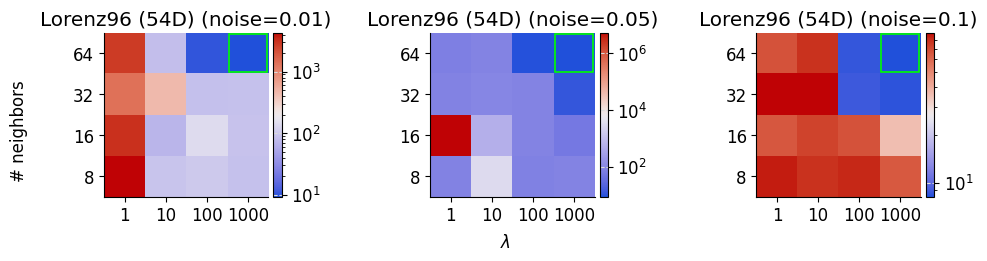

In [21]:
fig = perform_sweeps(
    "lorenz96_54d",
    "efficient_neighborhood",
    [(8, 16, 32, 64), (1, 10, 100, 1000)],
    subdir_fn=lambda num_neighbors,
    weight: f"smaller_radius/{num_neighbors=}_{weight=}",
    figsize=(10, 2.5),
    constrained_layout=True,
    gridspec_kw={"wspace": 0.04},
)
fig.supxlabel(r"$\lambda$", fontsize="medium")
fig.supylabel("# neighbors", fontsize="medium")

../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=8_weight=1
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=8_weight=10
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=8_weight=100
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=8_weight=1000
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=16_weight=1
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=16_weight=10
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=16_weight=100
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=16_weight=1000
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=32_weight=1
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=32_weight=10
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=32_weight=100
../../results/take3/lorenz96_54d/efficient_neighborhood/num_neighbors=32_weight=1000
..

Text(0.02, 0.5, '# neighbors')

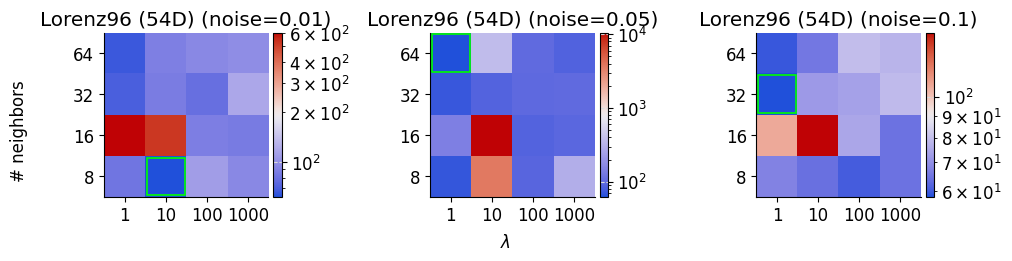

In [18]:
fig = perform_sweeps(
    "lorenz96_54d",
    "efficient_neighborhood",
    [(8, 16, 32, 64), (1, 10, 100, 1000)],
    subdir_fn=lambda num_neighbors, weight: f"{num_neighbors=}_{weight=}",
    figsize=(10, 2.5),
    constrained_layout=True,
    gridspec_kw={"wspace": 0.04},
)
fig.supxlabel(r"$\lambda$", fontsize="medium")
fig.supylabel("# neighbors", fontsize="medium")

../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=1
../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10/lr=0.002_noise=0.01_key=0/346'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10/lr=0.002_noise=0.01_key=0/4394'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10/lr=0.002_noise=0.01_key=0/867')]


/home/jhko725/projects/sandbox/packages/dynamics_discovery/src/dynamics_discovery/io.py:57: UserWarning: Given directory contains checkpoints from multiple steps. Returning the largest step.
  warnings.warn(


../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=100
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=100/lr=0.002_noise=0.01_key=0/4610'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=100/lr=0.002_noise=0.01_key=0/99')]
../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=1000
../../results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=1
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=1/lr=0.002_noise=0.01_key=0/1110'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=1/lr=0.002_noise=0.01_key=0/3102')]
../../results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=10
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=10/lr=0.002_noise=0.01_key=0/290'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=10/lr=0.002_noise=0.01_ke

Text(0.02, 0.5, '# neighbors')

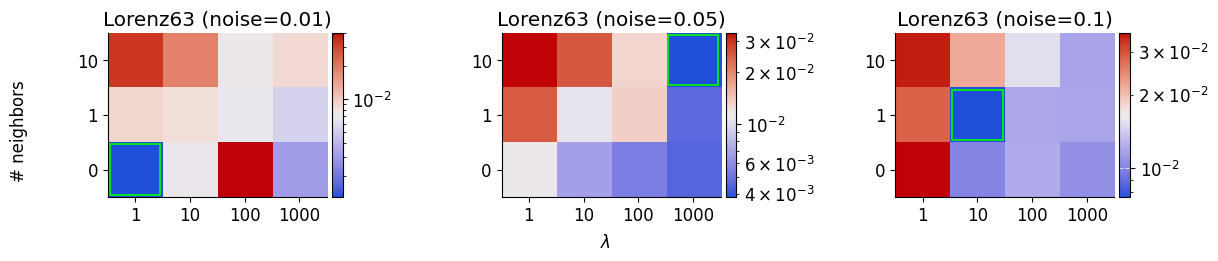

In [ ]:
fig = perform_sweeps(
    "lorenz63",
    "dyslim",
    [(0, 1, 10), (1, 10, 100, 1000)],
    subdir_fn=lambda lambda_1, lambda_2: f"{lambda_1=}_{lambda_2=}",
    figsize=(12, 2.5),
    constrained_layout=True,
    gridspec_kw={"wspace": 0.04},
)
fig.supxlabel(r"$\lambda_2$", fontsize="medium")
fig.supylabel(r"$\lambda_1$", fontsize="medium")

[((32, 1), Array(0.00116909, dtype=float64))]

In [24]:
sweep_results_into_grid(sinkhorns_sweep)

([[8, 16, 32, 64], [1, 10, 100, 1000]],
 array([[0.0052948 , 0.00126126, 0.00299553, 0.00303303],
        [0.00150099, 0.00338155, 0.00365262, 0.00303441],
        [0.00116909, 0.00404778, 0.00351995, 0.00406957],
        [0.00455265, 0.00500323, 0.00504582, 0.00430602]]))

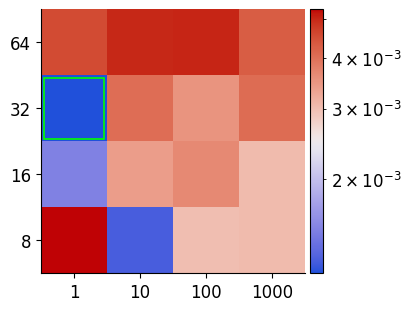

In [ ]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
ax = plot_sweep_results(ax, sinkhorns_sweep)

In [14]:
sinkhorns_sweep_dyslim = []
for lambda_1 in (0, 1, 10):
    for lambda_2 in (1, 10, 100, 1000):
        model = load_experiment(
            system_name,
            "dyslim",
            key=0,
            noise=0.01,
            subdir_fn=lambda lambda_1, lambda_2: f"{lambda_1=}_{lambda_2=}",
            lambda_1=lambda_1,
            lambda_2=lambda_2,
        )
        u_short_pred = solve_batch(model, dataset.t[0, :100], u_short[:, 0])
        sinkhorns_sweep_dyslim.append(
            sinkhorn_divergence(u_short[:, -1], u_short_pred[:, -1])
        )

../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=1
../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10/lr=0.002_noise=0.01_key=0/346'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10/lr=0.002_noise=0.01_key=0/4394'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=10/lr=0.002_noise=0.01_key=0/867')]
../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=100
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=100/lr=0.002_noise=0.01_key=0/4610'), PosixPath('/home/jhko725/projects/sandbox/results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=100/lr=0.002_noise=0.01_key=0/99')]
../../results/take3/lorenz63/dyslim/lambda_1=0_lambda_2=1000
../../results/take3/lorenz63/dyslim/lambda_1=1_lambda_2=1
[PosixPath('/home/jhko725/projects/sandbox/results/take3/lo

In [16]:
sinkhorns_sweep_dyslim = jnp.asarray(sinkhorns_sweep_dyslim)
print(sinkhorns_sweep_dyslim)
print(jnp.nanargmin(sinkhorns_sweep_dyslim))

[0.00129784 0.00686753 0.04038914 0.00307924 0.0088576  0.00831685
 0.00683212 0.00538901 0.03273807 0.01858203 0.00713518 0.00874389]
0


In [13]:
sinkhorns_sweep_vanilla = []

try:
    model = load_experiment(
        system_name,
        "vanilla",
        key=0,
        noise=0.01,
    )
except ValueError:
    sinkhorns_sweep_vanilla.append(jnp.asarray(jnp.nan))
u_short_pred = solve_batch(model, dataset.t[0, :100], u_short[:, 0])
sinkhorns_sweep_vanilla.append(sinkhorn_divergence(u_short[:, -1], u_short_pred[:, -1]))

../../results/take3/lorenz63/vanilla


In [21]:
sinkhorns_sweep_vanilla

[Array(1293.19502987, dtype=float64)]